# EDA — VIP Prediction Dataset

Мета — дослідити структуру та якість датасету `data/test_dataset.xlsx`,
знайти гіпотетичні помилки й аномалії та перевірити узгодженість показників
між листами — перед feature engineering і навчанням моделі. Прогноз VIP
(LTV >= 5000) має узагальнюватись на інший workbook з тими самими
стовпчиками A-K, але іншою кількістю користувачів, тож висновки нижче
сформульовані як загальні правила, а не прив'язки до конкретних чисел цього
файлу.

Ноутбук виконується напряму з `data/test_dataset.xlsx` через `src.data` —
усі числа обчислені в клітинках коду, нічого не хардкодиться.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_users, load_deposits, split_features_and_labels, N_FEATURE_COLUMNS

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

users = load_users()
deposits = load_deposits()
features, labels = split_features_and_labels(users)

print("users shape:", users.shape)
print("features (A-K) shape:", features.shape)
print("labels (training-only columns) shape:", labels.shape)
print("deposits sheet present:", deposits is not None, "-> shape:", None if deposits is None else deposits.shape)


users shape: (48092, 14)
features (A-K) shape: (48092, 11)
labels (training-only columns) shape: (48092, 3)
deposits sheet present: True -> shape: (189171, 4)


## 1. Колонки A–K: значення, типи, релевантність для прогнозу

`N_FEATURE_COLUMNS = 11` — стовпці A–K це перші 11 колонок першого листа.
Усе після них (тут — L, M, N) training-only і для прогнозу недоступне.

In [2]:
features.dtypes.to_frame("dtype").assign(
    n_missing=features.isna().sum(),
    pct_missing=(features.isna().mean() * 100).round(2),
)

,dtype,n_missing,pct_missing
uid,str,0,0.00
дата фтд,datetime64[us],0,0.00
дата і час реєстрації,datetime64[us],0,0.00
середній розмір бету на спін,float64,1056,2.20
к-ть спінів в день фтд,float64,1056,2.20
поштовий домен,str,0,0.00
дата встановлення застосунку в період до дня фтд включно,datetime64[us],37821,78.64
невдалих депозитів до дня фтд влючно,int64,0,0.00
сума депозитів в день фтд,float64,0,0.00
к-ть транзакцій в день фтд,int64,0,0.00


| Колонка (A-K) | Зміст | Тип | Доступна в момент прогнозу? | Відносна релевантність |
|---|---|---|---|---|
| A `uid` | ідентифікатор користувача | id | так | тільки ключ, не фіча |
| B `дата фтд` | дата/час першого депозиту | datetime | так (момент прогнозу = день FTD) | база для похідних ознак (день тижня, час доби) |
| C `дата і час реєстрації` | дата реєстрації акаунту | datetime | так | у поєднанні з B дає "час до конверсії" (сплячий акаунт vs миттєва конверсія) |
| D `середній розмір бету на спін` | середня ставка за спін у день FTD | float | так | поведінкова ознака, частково пропущена |
| E `к-ть спінів в день фтд` | к-ть спінів у день FTD | float | так | інтенсивність гри, частково пропущена |
| F `поштовий домен` | домен email | категоріальна | так | проксі каналу/сегмента/бренду |
| G `дата встановлення застосунку ...` | дата інсталяції застосунку | datetime | так | сильно розріджена (~20% заповнення) — проксі каналу app vs web |
| H `невдалих депозитів до дня фтд включно` | к-ть невдалих спроб депозиту | int | так | Кількість невдалих спроб депозиту; потенційно додатковий поведінковий сигнал |
| I `сума депозитів в день фтд` | сума депозитів у день FTD | float | так | очевидна, але задача явно просить НЕ спиратись лише на неї |
| J `к-ть транзакцій в день фтд` | к-ть депозитних транзакцій у день FTD | int | так | поведінкова, не грошова ознака |
| K `середні чек транзакції в день фтд` | середній чек транзакції у день FTD | float | так | у парі з J майже точно відновлює I (I ≈ J·K) |

**Важливо:** `J` і `K` разом майже точно відновлюють `I` (`I ≈ J·K`,
перевірила нижче) — тобто навіть без `I` у фічах модель бачить дуже близьку
комбінацію через `J`+`K`. Це не лікедж (усі три доступні в момент FTD), але
означає, що "не спиратись на суму спенду" — це про вагу конкретної колонки
`I`, а не про повну відсутність спенд-сигналу.

Жодна з колонок A–K сама по собі не є лікеджем — усі доступні вже в момент FTD.

## 2. Пропущені значення та дублікати (A–K)

In [3]:
print("=== Повні дублікати рядків ===")
print("users:", users.duplicated().sum())
print("дублікати uid:", users['uid'].duplicated().sum())

print("\n=== Пропуски в A-K ===")
print(features.isna().sum())

=== Повні дублікати рядків ===
users: 0
дублікати uid: 0

=== Пропуски в A-K ===
uid                                                             0
дата фтд                                                        0
дата і час реєстрації                                           0
середній розмір бету на спін                                 1056
к-ть спінів в день фтд                                       1056
поштовий домен                                                  0
дата встановлення застосунку в період до дня фтд включно    37821
невдалих депозитів до дня фтд влючно                            0
сума депозитів в день фтд                                       0
к-ть транзакцій в день фтд                                      0
середні чек транзакції в день фтд                               0
dtype: int64


In [4]:
missing_install = features['дата встановлення застосунку в період до дня фтд включно'].isna().mean()
missing_spins = features['к-ть спінів в день фтд'].isna().mean()
print(f"G (install date) відсутня у {missing_install:.1%} рядків")
print(f"D/E (bet size / spins) відсутні одночасно у {missing_spins:.1%} рядків")

implied_i = features['к-ть транзакцій в день фтд'] * features['середні чек транзакції в день фтд']
match_rate = (abs(implied_i - features['сума депозитів в день фтд']) < 1.0).mean()
print(f"\nI ≈ J·K (різниця < 1): {match_rate:.1%} рядків")

G (install date) відсутня у 78.6% рядків
D/E (bet size / spins) відсутні одночасно у 2.2% рядків

I ≈ J·K (різниця < 1): 100.0% рядків


**Спостереження / проблеми якості даних:**
- `G` заповнена лише для ~20% користувачів; незрозуміло, чи NaN означає
  відсутність застосунку, чи що канал просто не відстежувався.
- `D`/`E` відсутні одночасно для ~2% користувачів — можливо, інший тип гри
  в день FTD (live-казино, спорт), але це лише гіпотеза.
- Непослідовні пробіли в назвах колонок — технічна дрібниця, виправлена в
  `src/data.py` (`.strip()`).

## 3. Ціль (training-only) та дисбаланс класів

`L` (`віп/не віп`) присутня лише в тренувальному файлі — ЕDA тут потрібна, щоби
зрозуміти складність задачі, але сама колонка НЕ ввійде у фічі.


віп/не віп
0    46937
1     1155
Name: count, dtype: int64

VIP rate: 2.40%  (imbalance ~ 1:41)


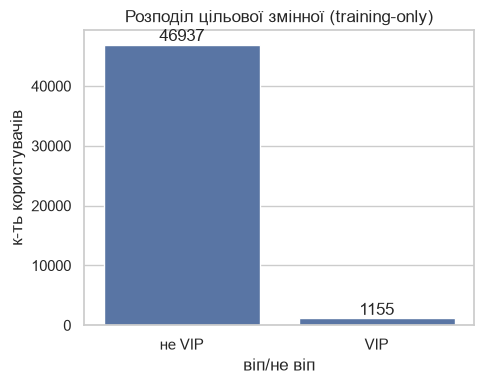

In [5]:
vip_col = labels['віп/не віп'] if 'віп/не віп' in labels.columns else None
if vip_col is not None:
    vip_counts = vip_col.value_counts().sort_index()
    vip_rate = vip_col.mean()
    print(vip_counts)
    print(f"\nVIP rate: {vip_rate:.2%}  (imbalance ~ 1:{(1-vip_rate)/vip_rate:.0f})")

    fig, ax = plt.subplots(figsize=(5, 4))
    sns.barplot(x=vip_counts.index.map({0: "не VIP", 1: "VIP"}), y=vip_counts.values, ax=ax)
    ax.set_ylabel("к-ть користувачів")
    ax.set_title("Розподіл цільової змінної (training-only)")
    for i, v in enumerate(vip_counts.values):
        ax.text(i, v, f"{v}", ha="center", va="bottom")
    plt.tight_layout()
    plt.show()
else:
    print("Ціль відсутня в цьому файлі (ознака, що це вже evaluation-формат)")

Сильний дисбаланс класів (VIP ≈ 2.4%) робить accuracy малоінформативною —
модель, що завжди прогнозує "не VIP", мала б accuracy ~97.6% і нуль
користі. Для цього завдання важливі саме recall (частка реальних VIP, що
потрапили в прогноз) і кількість прогнозованих VIP — обидва підбираються на
тренувальних даних так, щоб узагальнювались на датасет іншого розміру.

## 4. Базова числова статистика (A–K)

In [6]:
num_cols = [
    'середній розмір бету на спін', 'к-ть спінів в день фтд',
    'невдалих депозитів до дня фтд влючно', 'сума депозитів в день фтд',
    'к-ть транзакцій в день фтд', 'середні чек транзакції в день фтд',
]
features[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
середній розмір бету на спін,47036.0,0.941600,3.449351,0.0000,0.274694,0.502332,0.965553,237.653448
к-ть спінів в день фтд,47036.0,950.991623,1461.629099,1.0000,177.000000,443.000000,1107.000000,25275.000000
невдалих депозитів до дня фтд влючно,48092.0,0.947413,2.299976,0.0000,0.000000,0.000000,1.000000,101.000000
сума депозитів в день фтд,48092.0,49.538114,118.230713,0.2658,19.819887,24.328000,41.392870,4252.380374
к-ть транзакцій в день фтд,48092.0,1.593529,1.706588,1.0000,1.000000,1.000000,2.000000,61.000000
середні чек транзакції в день фтд,48092.0,26.543512,22.572649,0.2700,19.640000,21.050000,25.240000,1036.320000


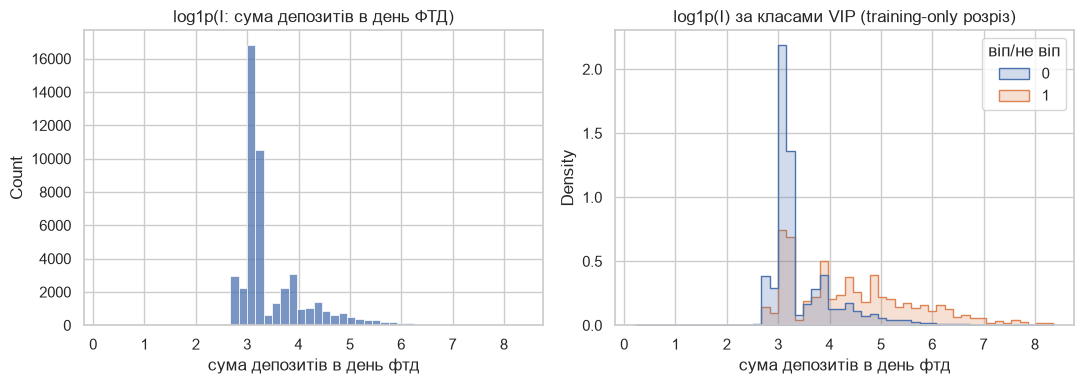

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(np.log1p(features['сума депозитів в день фтд']), bins=50, ax=axes[0])
axes[0].set_title("log1p(I: сума депозитів в день ФТД)")
if vip_col is not None:
    sns.histplot(x=np.log1p(features['сума депозитів в день фтд']), hue=vip_col, bins=50,
                 ax=axes[1], element="step", stat="density", common_norm=False)
    axes[1].set_title("log1p(I) за класами VIP (training-only розріз)")
plt.tight_layout()
plt.show()

**Спостереження:** фінансові ознаки (I, K) мають важкий правий хвіст. I частково розділяє класи, але з великим перекриттям.

## 5. Зв'язок між Лист1 (A-K+) та Лист2

Лист2 — сирий журнал депозитних транзакцій (`user_id`, `dep1`,
`to_timestamp`). Перевірила: чи потрібен цей лист фінальному пайплайну, що
означає колонка `Unnamed: 3`, і чи коректно побудовані training-only
колонки `M` (`деп 60 днів`) і `N` (`ltv`).

In [8]:
if deposits is not None:
    uids_users = set(users['uid'])
    uids_deposits = set(deposits['user_id'])
    print("Унікальних uid у users:", len(uids_users))
    print("Унікальних user_id у deposits:", len(uids_deposits))
    print("Перетин:", len(uids_users & uids_deposits))
    print("Тільки в users (orphan 'no deposits'):", len(uids_users - uids_deposits))
    print("Тільки в deposits (orphan transactions):", len(uids_deposits - uids_users))

    tx_per_user = deposits.groupby('user_id').size()
    print("\nТранзакцій на користувача:")
    print(tx_per_user.describe())

    print("\ndep1 (сума однієї транзакції) describe:")
    print(deposits['dep1'].describe())
    print("dep1 <= 0:", (deposits['dep1'] <= 0).sum())
    print("дублікати (user_id, dep1, to_timestamp):", deposits.duplicated(subset=['user_id', 'dep1', 'to_timestamp']).sum())
else:
    print("Другого листа немає в цьому файлі.")

Унікальних uid у users: 48092
Унікальних user_id у deposits: 48092
Перетин: 48092
Тільки в users (orphan 'no deposits'): 0
Тільки в deposits (orphan transactions): 0

Транзакцій на користувача:
count    48092.000000
mean         3.933523
std         11.325937
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max        247.000000
dtype: float64

dep1 (сума однієї транзакції) describe:
count    189171.000000
mean         93.985594
std         235.334886
min           0.265800
25%          21.266132
50%          36.234228
75%          79.803301
max       14700.213990
Name: dep1, dtype: float64
dep1 <= 0: 0
дублікати (user_id, dep1, to_timestamp): 0


### 5.1 Транзакції до дня FTD (цілісність визначення "перший депозит")

In [9]:
if deposits is not None:
    ftd_day = users.set_index('uid')['дата фтд'].dt.floor('D')
    tx = deposits.merge(ftd_day.rename('ftd_day'), left_on='user_id', right_index=True, how='left')
    tx['days_since_ftd'] = (tx['to_timestamp'] - tx['ftd_day']).dt.days
    before_ftd = tx['days_since_ftd'] < 0
    print("Транзакцій РАНІШЕ дня FTD (мало б бути 0):", before_ftd.sum(), "/", len(tx))

Транзакцій РАНІШЕ дня FTD (мало б бути 0): 0 / 189171


### 5.2 Що таке `Unnamed: 3`?

Перевірила гіпотезу: це кумулятивна сума `dep1` для кожного користувача, у
порядку рядків листа (а не сума однієї транзакції й не метрика по всій
платформі).

In [10]:
if deposits is not None:
    cumsum_per_user = deposits.groupby('user_id')['dep1'].cumsum()
    match_cumsum_user = np.isclose(deposits['Unnamed: 3'], cumsum_per_user, atol=0.01)
    print(f"Unnamed: 3 == кумулятивна сума dep1 ПО КОРИСТУВАЧУ: {match_cumsum_user.mean():.4%} рядків ({match_cumsum_user.sum()}/{len(deposits)})")

    equal_to_dep1 = np.isclose(deposits['Unnamed: 3'], deposits['dep1'], atol=0.01)
    print(f"Unnamed: 3 == dep1 (лише перша транзакція користувача): {equal_to_dep1.sum()} рядків")

Unnamed: 3 == кумулятивна сума dep1 ПО КОРИСТУВАЧУ: 100.0000% рядків (189171/189171)
Unnamed: 3 == dep1 (лише перша транзакція користувача): 48092 рядків


**Висновок:** `Unnamed: 3` на 100% пояснюється як кумулятивна сума `dep1`
по кожному `user_id`, у наявному порядку рядків — технічний артефакт, не
окрема метрика. Для першої транзакції користувача вона збігається з `dep1`
(звідси враження "часткового збігу" на перший погляд). Жодної інформації
понад `dep1`+`user_id`+`to_timestamp` не несе і як фіча не використовується.

### 5.3 Реконсиляція `I`, `M` (`деп 60 днів`) і `N` (`ltv`) з журналу транзакцій

Вікно для `M` — **дні [0, 60] включно відносно дня FTD (61 день)**.
Перевірила обидва варіанти меж явно, щоб зафіксувати правильне визначення.

In [11]:
if deposits is not None:
    for lo, hi, label in [(0, 59, "[0,59] включно (60 днів)"), (0, 60, "[0,60] включно (61 день)")]:
        window = tx[(tx['days_since_ftd'] >= lo) & (tx['days_since_ftd'] <= hi)]
        sums = window.groupby('user_id')['dep1'].sum()
        check = users.set_index('uid')['деп 60 днів'].to_frame().join(sums.rename('sum_window')).fillna(0)
        match = (abs(check['деп 60 днів'] - check['sum_window']) < 0.01).mean()
        print(f"Вікно {label}: збіг з 'деп 60 днів' = {match:.4%}")

Вікно [0,59] включно (60 днів): збіг з 'деп 60 днів' = 98.5798%
Вікно [0,60] включно (61 день): збіг з 'деп 60 днів' = 99.9979%


In [12]:
if deposits is not None:
    # коректне вікно [0,60] включно
    window = tx[(tx['days_since_ftd'] >= 0) & (tx['days_since_ftd'] <= 60)]
    sum60 = window.groupby('user_id')['dep1'].sum()
    sum_day0 = tx.loc[tx['days_since_ftd'] == 0].groupby('user_id')['dep1'].sum()
    sum_all = tx.groupby('user_id')['dep1'].sum()

    check = users.set_index('uid')[['сума депозитів в день фтд', 'деп 60 днів', 'ltv']].join(
        sum_day0.rename('sum_day0')).join(sum60.rename('sum60')).join(sum_all.rename('sum_all'))
    check[['sum_day0', 'sum60', 'sum_all']] = check[['sum_day0', 'sum60', 'sum_all']].fillna(0)

    match_i = (abs(check['sum_day0'] - check['сума депозитів в день фтд']) < 0.01).mean()
    match_m = (abs(check['sum60'] - check['деп 60 днів']) < 0.01).mean()
    match_n = (abs(check['sum_all'] - check['ltv']) < 0.01).mean()
    print(f"I  (сума в день ФТД)      == сума dep1 за день 0:        {match_i:.4%}")
    print(f"M  (деп 60 днів, [0,60])  == сума dep1 за 61 день:       {match_m:.4%}")
    print(f"N  (ltv)                  == сума ВСІХ dep1 користувача: {match_n:.4%}")

    print("\nЄдина розбіжність по M (якщо є):")
    bad_m = check[abs(check['sum60'] - check['деп 60 днів']) >= 0.01]
    print(bad_m[['деп 60 днів', 'sum60']])

I  (сума в день ФТД)      == сума dep1 за день 0:        99.9958%
M  (деп 60 днів, [0,60])  == сума dep1 за 61 день:       99.9979%
N  (ltv)                  == сума ВСІХ dep1 користувача: 91.3645%

Єдина розбіжність по M (якщо є):
                                      деп 60 днів     sum60
uid                                                        
9ddb4f58-b311-4bd4-8394-1d07c2fc76d4          0.0  56.74937


In [13]:
if deposits is not None:
    bad_i = check[abs(check['sum_day0'] - check['сума депозитів в день фтд']) >= 0.01]
    print(f"Розбіжність I vs сума dep1 за день FTD: {len(bad_i)} рядок(и)")
    print(bad_i[['сума депозитів в день фтд', 'sum_day0']])
    print("\nПеретин з аномалією по M:", set(bad_i.index) & set(bad_m.index))

    for uid in bad_i.index:
        tx_count_l1 = users.set_index('uid').loc[uid, 'к-ть транзакцій в день фтд']
        print(f"\n{uid}: 'к-ть транзакцій в день фтд' у Лист1 = {tx_count_l1}")
        print(tx[tx['user_id'] == uid][['to_timestamp', 'dep1', 'days_since_ftd']].to_string(index=False))

Розбіжність I vs сума dep1 за день FTD: 2 рядок(и)
                                      сума депозитів в день фтд   sum_day0
uid                                                                       
5f047393-0b40-4c5d-8379-eadfff45cd97                  44.180792  23.389831
7e92485b-dc3b-4c62-8a70-6f8e4ce85ebe                  41.261392  20.630696

Перетин з аномалією по M: set()

5f047393-0b40-4c5d-8379-eadfff45cd97: 'к-ть транзакцій в день фтд' у Лист1 = 2
to_timestamp      dep1  days_since_ftd
  2025-03-06 23.389831               0

7e92485b-dc3b-4c62-8a70-6f8e4ce85ebe: 'к-ть транзакцій в день фтд' у Лист1 = 2
to_timestamp       dep1  days_since_ftd
  2025-03-28  20.630696               0
  2025-03-29  41.444743               1
  2025-03-30  49.225195               2
  2025-03-31 140.056059               3
  2025-04-01 376.201031               4
  2025-04-03 179.900664               6
  2025-04-04 109.969436               7
  2025-04-05 138.801424               8
  2025-04-07  15.4

**Висновок по I:** 2 розбіжності, обидві — інші uid, ніж аномалія по M.
В обох випадках `Лист1` фіксує `к-ть транзакцій в день фтд = 2`, а в
`Лист2` на календарну дату FTD видно лише одну транзакцію — другої транзакції за календарний день FTD у наданому журналі не знайшла. Механізм інший, ніж у аномалії по M (там транзакція є, але
не врахована у `деп 60 днів`); тут навпаки — Лист1 "очікує" другу
транзакцію, якої в Лист2 немає.

**Висновок по M:** з правильним вікном [0,60] включно (61 день) збіг майже
ідеальний (99.998%). Раніше повідомлені "98.6%" — наслідок мого ж
невірного визначення меж вікна ([0,59] замість [0,60]), а не проблема
датасету. Залишається один реальний аномальний рядок (вище) — `деп 60 днів
= 0` при наявному депозиті в день FTD.

### 5.4 `N` (ltv) vs видимі транзакції

Точне бізнес-визначення `ltv` невідоме — за умовою задачі це цільова
метрика з порогом 5000. Перевірила емпірично, чи узгоджується `ltv` із
сумою всіх видимих `dep1`: знак розбіжності, величину, і чи концентрується
вона серед VIP.

In [14]:
if deposits is not None:
    check['diff_n'] = check['ltv'] - check['sum_all']
    mismatched = check['diff_n'].abs() >= 0.01
    print(f"Розбіжність ltv vs sum(dep1): {mismatched.sum()} / {len(check)} ({mismatched.mean():.2%})")
    print("знак: ltv > sum (позитивна):", (check.loc[mismatched, 'diff_n'] > 0).sum(),
          "   ltv < sum (негативна):", (check.loc[mismatched, 'diff_n'] < 0).sum())
    print(check.loc[mismatched, 'diff_n'].describe())

Розбіжність ltv vs sum(dep1): 4153 / 48092 (8.64%)
знак: ltv > sum (позитивна): 4147    ltv < sum (негативна): 6
count      4153.000000
mean       3488.261593
std       10987.096520
min         -50.678304
25%          66.430350
50%         310.716905
75%        2192.898828
max      319478.551907
Name: diff_n, dtype: float64


In [15]:
if deposits is not None and vip_col is not None:
    check['vip'] = users.set_index('uid')['віп/не віп']
    n_vip = int((check['vip'] == 1).sum())
    n_nonvip = int((check['vip'] == 0).sum())
    print(f"Частка розбіжності серед VIP:     {mismatched[check['vip'] == 1].mean():.2%}  (n_vip={n_vip})")
    print(f"Частка розбіжності серед не-VIP:  {mismatched[check['vip'] == 0].mean():.2%}  (n_nonvip={n_nonvip})")

    invisible_vip = (check['sum_all'] < 5000) & (check['vip'] == 1)
    n_invisible = int(invisible_vip.sum())
    print(f"\n'Невидимі' VIP (ltv>=5000, але сума видимих депозитів < 5000): {n_invisible} / {n_vip} VIP ({n_invisible / n_vip:.1%})")

    median_frac_missing = (check.loc[mismatched & (check['vip'] == 1), 'diff_n'] / check.loc[mismatched & (check['vip'] == 1), 'ltv']).median()
    print(f"Серед VIP з розбіжністю: медіанна частка ltv поза видимими депозитами = {median_frac_missing:.1%}")

Частка розбіжності серед VIP:     87.79%  (n_vip=1155)
Частка розбіжності серед не-VIP:  6.69%  (n_nonvip=46937)

'Невидимі' VIP (ltv>=5000, але сума видимих депозитів < 5000): 487 / 1155 VIP (42.2%)
Серед VIP з розбіжністю: медіанна частка ltv поза видимими депозитами = 60.1%


Розбіжність між `ltv` і видимими депозитами Лист2 не випадкова — вона
сконцентрована серед VIP: більшість VIP-користувачів мають частину (а часто
й більшість) `ltv`, що не підтверджується видимим журналом транзакцій. Для
частини VIP видимі депозити взагалі ніколи не перетинають поріг 5000. Я
перевіряла лише Лист2 — що саме формує цю різницю, лишається відкритим
питанням (розділ "Питання для уточнення").

### 5.5 Розріз по когортах (місяць FTD): чи стабільна ця розбіжність у часі?

         n_vip  invisible_share
month                          
2024-09    159         0.238994
2024-10    182         0.296703
2024-11    178         0.359551
2024-12    140         0.385714
2025-01    144         0.486111
2025-02     87         0.551724
2025-03     85         0.541176
2025-04     78         0.551282
2025-05    102         0.686275


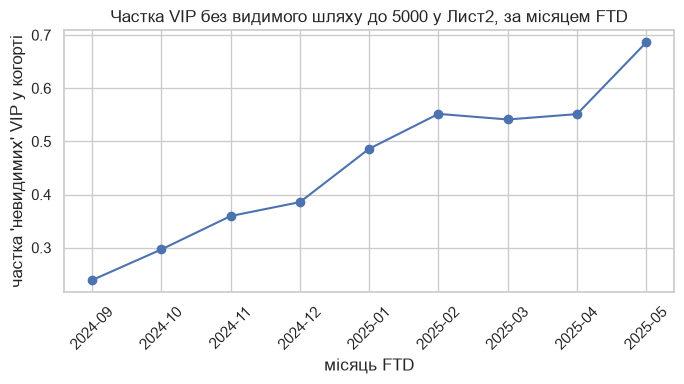

In [16]:
if deposits is not None and vip_col is not None:
    vip_rows = check[check['vip'] == 1].join(users.set_index('uid')['дата фтд'])
    vip_rows['month'] = vip_rows['дата фтд'].dt.to_period('M')
    vip_rows['invisible'] = vip_rows['sum_all'] < 5000
    cohort = vip_rows.groupby('month').agg(n_vip=('invisible', 'size'), invisible_share=('invisible', 'mean'))
    print(cohort)

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(cohort.index.astype(str), cohort['invisible_share'], marker='o')
    ax.set_ylabel("частка 'невидимих' VIP у когорті")
    ax.set_xlabel("місяць FTD")
    ax.set_title("Частка VIP без видимого шляху до 5000 у Лист2, за місяцем FTD")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

**Спостереження:** частка "невидимих" VIP зростає майже монотонно від
ранніх до пізніх когорт FTD. Два можливі, не взаємовиключні пояснення, які
не розділити на одному знімку даних:
1. зростаюча частка доходу поза депозитами Лист2 (інший платіжний канал,
   бонусний механізм, зміна визначення `ltv` з часом);
2. коротше вікно спостереження для пізніх когорт — менше часу накопичити
   видимі депозити до 5000, незалежно від справжньої траєкторії
   користувача (те саме явище, що в п. 5.3, тепер видиме на рівні `ltv`).

Обидва пояснення — гіпотези: підтверджено лише те, що видимий журнал
депозитів не пояснює зростаючу частку `ltv` для пізніх когорт.

## 6. Додаткові розрізи поведінки користувача (A–K)

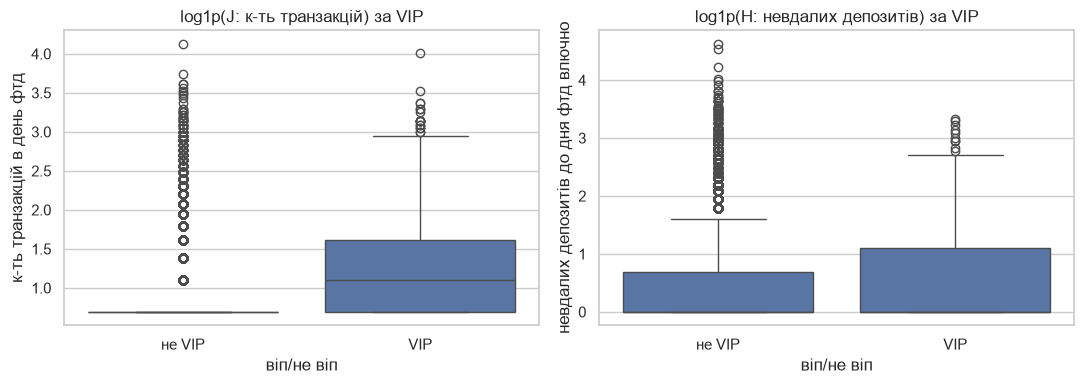

In [17]:
if vip_col is not None:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    sns.boxplot(x=vip_col, y=np.log1p(features['к-ть транзакцій в день фтд']), ax=axes[0])
    axes[0].set_title("log1p(J: к-ть транзакцій) за VIP")
    axes[0].set_xticks([0, 1])
    axes[0].set_xticklabels(["не VIP", "VIP"])

    sns.boxplot(x=vip_col, y=np.log1p(features['невдалих депозитів до дня фтд влючно']), ax=axes[1])
    axes[1].set_title("log1p(H: невдалих депозитів) за VIP")
    axes[1].set_xticks([0, 1])
    axes[1].set_xticklabels(["не VIP", "VIP"])
    plt.tight_layout()
    plt.show()

In [18]:
top_domains = features['поштовий домен'].value_counts().head(10).index
if vip_col is not None:
    domain_stats = (
        pd.DataFrame({'domain': features['поштовий домен'], 'vip': vip_col})
        .loc[lambda d: d['domain'].isin(top_domains)]
        .groupby('domain')['vip']
        .agg(['mean', 'count'])
        .sort_values('mean', ascending=False)
    )
    domain_stats.columns = ['vip_rate', 'count']
    display(domain_stats)
else:
    print(features['поштовий домен'].value_counts().head(10))

,vip_rate,count
domain,,
icloud.com,0.043071,534
onet.pl,0.041280,969
interia.pl,0.036422,1867
wp.pl,0.027494,6365
o2.pl,0.026199,2252
op.pl,0.024857,1046
gmail.com,0.023632,28478
slottyway.com,0.000691,1448
allrightcasino.com,0.000000,719


In [19]:
has_install = features['дата встановлення застосунку в період до дня фтд включно'].notna()
gap_days = (features['дата фтд'] - features['дата і час реєстрації']).dt.days
print("gap_days (реєстрація -> FTD), describe:")
print(gap_days.describe())
if vip_col is not None:
    print("\nVIP rate з датою встановлення застосунку:   ", vip_col[has_install].mean())
    print("VIP rate без дати встановлення застосунку:   ", vip_col[~has_install].mean())
    print("VIP rate для 'сплячих' акаунтів (gap > 365 д):", vip_col[gap_days > 365].mean())
    print("VIP rate для інших (gap <= 365 д):            ", vip_col[gap_days <= 365].mean())

gap_days (реєстрація -> FTD), describe:
count    48092.000000
mean        58.323796
std        227.620946
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max       2307.000000
dtype: float64

VIP rate з датою встановлення застосунку:    0.029792619998052768
VIP rate без дати встановлення застосунку:    0.022447846434520503
VIP rate для 'сплячих' акаунтів (gap > 365 д): 0.03630223723089911
VIP rate для інших (gap <= 365 д):             0.023379918203092535


**Спостереження:**
- Кілька email-доменів мають VIP rate помітно нижчий/вищий за середній і
  виглядають не як звичайні email-провайдери, а радше як бренд- чи
  платформо-подібні значення — природа цього не перевірена.
- `gap_days` (реєстрація → FTD) має широкий розкид; "сплячі" акаунти
  показують дещо інший VIP rate — робоча гіпотеза для фічі, не остаточний
  висновок.
- `H` (невдалі депозити) характеризує інший аспект поведінки користувача,
  ніж сума депозиту — статистичну незалежність від `I` не перевіряла, але
  це потенційно додаткова інформація для моделі. `J` (к-ть транзакцій) теж
  поведінковий, і в парі з `K` частково відновлює `I` (`I ≈ J·K`, п.1).

## 7. Prediction-time features vs training-only — підсумок

**Доступно в момент прогнозу (A–K):** усі колонки з розділу 1, крім `uid`
(лише ключ).

**Training-only, поза A–K:** `віп/не віп` (ціль), `ltv` (визначення цілі:
`VIP ⟺ ltv >= 5000`; частина VIP не підтверджується видимими депозитами,
п.5.4), `деп 60 днів` (депозити за [0,60] днів від FTD — дані з майбутнього
відносно моменту прогнозу).

Виключення `I` з фіч не прибирає весь спендовий сигнал дня FTD — `J`+`K`
залишаються й відновлюють `I` майже точно (п.1). "Не спиратись на суму
спенду" варто розуміти як "не покладатись лише на цю агреговану колонку",
а не як відсутність фінансового сигналу.

## 8. Питання для уточнення

1. **Як саме розраховується LTV?** У 8,64% користувачів LTV не збігається із сумою депозитів у Лист2, а для 42,2% VIP сума видимих депозитів навіть не досягає 5000. Чи враховуються тут інші джерела доходу, додаткові транзакції або інша логіка розрахунку?

2. **Чи всі транзакції є в Лист2?** Знайшла дві розбіжності із сумою депозитів у день FTD та одну з депозитами за 60 днів. Хотіла б уточнити, чи це неповні дані, чи показники в Лист1 та Лист2 розраховуються по-різному.

3. **Що означають пропуски в D, E та G?** Це відсутність активності або встановленого застосунку чи просто відсутні дані?

4. **Чи будуть у новому датасеті ті самі ознаки A–K?** Зокрема, чи всі вони будуть доступні на момент прогнозу та матимуть ті самі визначення?

## 9. Підсумок

- A–K (11 колонок) — єдині легітимні prediction-time фічі; `I` частково
  відновлюється через `J·K` навіть без неї у фічах.
- L/M/N — training-only. `M` з правильним 61-денним вікном збігається з
  журналом транзакцій на 99.998% (1 аномалія). `Unnamed: 3` — кумулятивна
  сума `dep1` по користувачу, не фіча.
- `ltv` не узгоджується з видимими депозитами Лист2 для 8.64% користувачів,
  переважно серед VIP: для 487 з 1155 VIP (42.2%) сума в доступному журналі
  не досягає 5000 — це не доводить, що решта депозитів відсутня взагалі,
  лише що видимий журнал їх не містить. Частка таких випадків зростає з
  часом. Причина не встановлена — гіпотези в розділі 8.
- Лист2 використала для перевірки агрегатів та аналізу розбіжностей; для прогнозу він не потрібен.
- Дисбаланс класів (VIP ≈ 2.4%) визначає вибір метрик і порогу моделі.

Деталі моделювання — в `src/` та `README.md`.